# Markov Chain

## Why Chosen

From the previous sprint we have a solid baseline model which can be futher developed and improved. There are many ways in which the model can be adjusted in this section we will cover 4 main ways in which we can do this:
 - Two Class Chain
 - Segmentation of States
 - Adding supplimentary data 
 - TBD

As each adjustment is made we will compare against the baseline model to see how the results are affected, then compare each model against one another and crown one of them as the strongest.

## Requirements

In [103]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    accuracy_score, recall_score, precision_score,
    precision_recall_curve, average_precision_score,
)

## Data

In [104]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


## Performance Metrics

Below are the functions for all the performance metrics which will be looked at throughout this notebook. --- *explain the choices why they are appropriate*

In [105]:
ys = {"train": y_tr, "val": y_va, "test": y_te}   # target arrays per split

def _probs(m, split):
    key = {"train": "p_tr", "val": "p_va", "test": "p_te"}[split]
    if key in m:
        return np.asarray(m[key])
    sc = m[{"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]]
    return m["platt"].predict_proba(np.asarray(sc).reshape(-1, 1))[:, 1]

def _grid(n, ncols=3, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        fpr, tpr, _ = roc_curve(ys[split], _probs(m, split))
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], _probs(m, split)):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p, r, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r, p, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="test", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="test", bins=40):
    sc_key = {"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="test", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

## Baseline Markov Chain Model

The code from the first sprint has been adjusted to fit with our consistent split of data so that the comparisons are completely fair. This single chain model is a good starting point firstly because it is simple and inexpensive with only 4 states. o

In [106]:
state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s
S_tr = to_state_ow(train[pay_cols].values)
S_va = to_state_ow(validation[pay_cols].values)
S_te = to_state_ow(test[pay_cols].values)
y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))
# 1) transition matrix (TRAIN only, Laplace smoothing)
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)
# 2) default rate by latest state, shrunk toward the global rate (TRAIN only)
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])
# 3) one-step Markov projection: P(default) = sum_j P[latest, j] * risk[j]
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state
p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)
pooled = dict(p_tr=predict_onestep(S_tr), p_va=p_mk_onestep_va, p_te=p_mk_onestep_te)

### 1. Shrink Analysis
The only tuning required for this model is shrink values. I varied the shrink vastly when looking at the model (between 0 and 2000) it did not affect the AUC but did increase log loss slightly so I will keep it relatively small as a safeguard.

In [107]:
for s in [0, 20, 200, 2000]:
    r = np.array([(y_tr_a[latest_tr == k].sum() + s * global_rate) /
                  ((latest_tr == k).sum() + s) for k in range(K_ow)])
    p = P_ow[S_va[:, -1]] @ r
    print(s, r.round(3), "order", np.argsort(r), "AUC", round(roc_auc_score(y_va_a, p), 5),
          "logloss", round(log_loss(y_va_a, p), 5))

0 [0.142 0.322 0.692 0.708] order [0 1 2 3] AUC 0.70983 logloss 0.45736
20 [0.142 0.322 0.686 0.676] order [0 1 3 2] AUC 0.70983 logloss 0.45792
200 [0.143 0.314 0.64  0.507] order [0 1 3 2] AUC 0.70983 logloss 0.46225
2000 [0.152 0.274 0.43  0.282] order [0 1 3 2] AUC 0.70931 logloss 0.48346


### 2.Performance

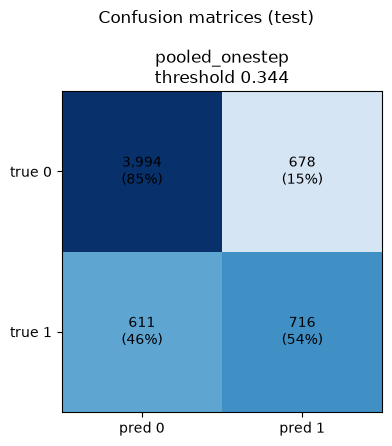

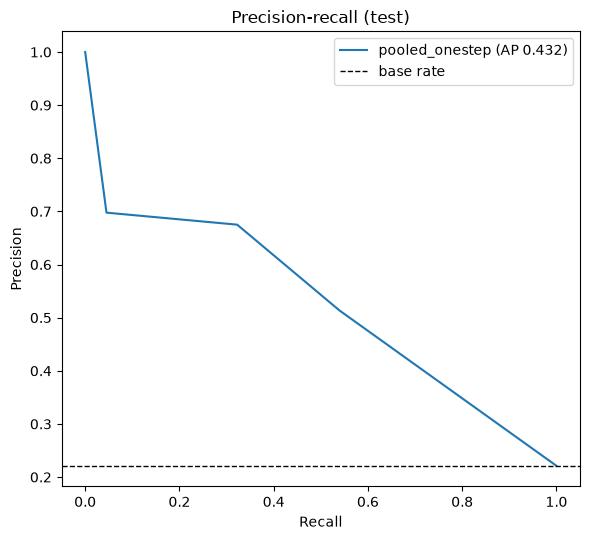

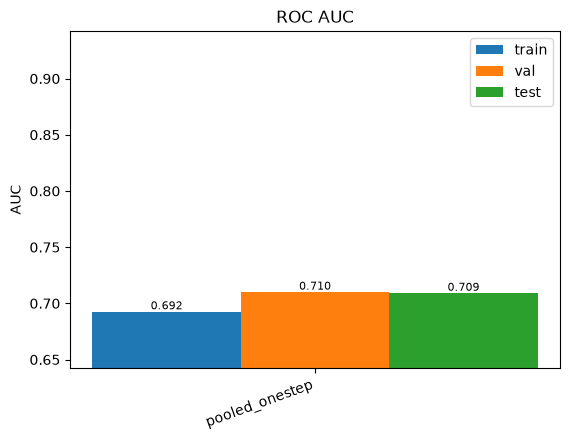

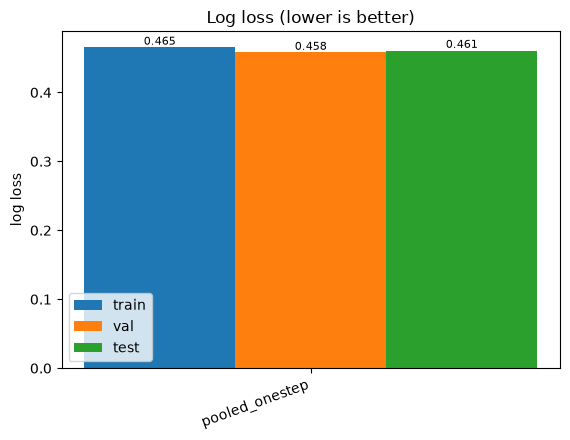

{'pooled_onestep': {'train': 0.465359809597765,
  'val': 0.45792257129597463,
  'test': 0.46078179195670793}}

In [108]:

plot_confusion({"pooled_onestep": pooled}, split="test")
plot_pr({"pooled_onestep": pooled})
plot_auc({"pooled_onestep": pooled})
plot_logloss({"pooled_onestep": pooled})

The AUC for validation and test data is almost identical. This is a good sign that the model definitely isnt overfit

### 3. Disadvantages of this Model

- The model is a one step transition so only cares about the latest state, treating someone who has been a month late 6 months going the same as someone who was current for the first 5 and late the most recent.
- By averaging state transitions it compresses extremes to a mean which leads to low risk being overestimated and high risk underestimated. This is likely why the model does well with non-defaulters but is almost 50/50 with defaulters.
- Pooling the two classes together leads to patterns of each class individually being hidden and averaging the behaviour of both. This is why the next model will train on each of the classes seperately, so their differences in behaviour can be better identified

## Two Class Chain

For this model the training data is seperated into default and non-default classes and a markov chain is fit to each of them 

### 1. Data and states

For each customer (`PAY_6, ..., PAY_1`) denotes their payment status and $y \in \{0, 1\}$ denotes defaults: $1$ = default next month. The state mappings send each status into a bin

$$x_t = g(\text{PAY}_t) \in \{1, \dots, K\}, \qquad \mathbf{x} = (x_1, x_2, \dots, x_T).$$

For the new two class model, we will fit it with different bins which we can then compare and see how it affects the results. I have chosen two inital data splits:
- each type of on time payment seperate, 
- combine all on time payments.

These first will give a 5 state chain while the second will only give a 4 state chain by also splitting the final state into two.

In [109]:
# ---- state mappings ----
def make_to_state(mapping, top):
    # mapping: dict raw value -> state; any raw value >= top maps to the last state
    def f(p):
        p = np.asarray(p); s = np.empty(p.shape, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        s[p >= top] = max(mapping.values()) + 1 if top > max(mapping) else mapping[top]
        return s
    return f
# #function for each split of the Markov model
#original 5 states
def to_state_5full(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

#merges -2, -1 and 0 into one state (not late)
def to_state_4nolate(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s


### 2. Fit one chain per class (train split only)
Let $\mathcal{D}_c = \{ i : y_i = c \}$ for $c \in \{0, 1\}$ and let $\alpha = 1$ be the Laplace constant.

**Initial distribution** (state in the first month):

$$\pi_c(s) = \frac{\alpha + \sum_{i \in \mathcal{D}_c} \mathbf{1}[x_{i,1} = s]}{|\mathcal{D}_c| + K\alpha}.$$

**Transition matrix** from pooled consecutive pairs:

$$N_c(a,b) = \sum_{i \in \mathcal{D}_c} \sum_{t=1}^{T-1} \mathbf{1}[x_{i,t} = a,\; x_{i,t+1} = b],$$

$$P_c(a,b) = \frac{N_c(a,b) + \alpha}{\sum_{b'} N_c(a,b') + K\alpha}, \qquad \sum_{b} P_c(a,b) = 1.$$

In [ ]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    #------2. Fit the Markov chain to the training data for each class (default and non-default)-------# 
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    
    #--------5. Fit a Platt scaling model to the validation set to calibrate the scores into probabilities.----------#
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build models ----
markov_models_1 = {
    "mk5_full":     build_markov("mk5_full",     to_state_5full,     5),
    "mk4_nolate":   build_markov("mk4_nolate",   to_state_4nolate,   4),
}

# named probability vectors, matching your existing p_mk_va / p_mk_te style
p_mk5_full_va,     p_mk5_full_te     = markov_models_1["mk5_full"]["p_va"],     markov_models_1["mk5_full"]["p_te"]
p_mk4_nolate_va,   p_mk4_nolate_te   = markov_models_1["mk4_nolate"]["p_va"],   markov_models_1 ["mk4_nolate"]["p_te"]

### 3. Sequence likelihood under each class
Assuming a first-order, time-homogeneous Markov chain:

$$\Pr(\mathbf{x} \mid y = c) = \pi_c(x_1) \prod_{t=1}^{T-1} P_c(x_t, x_{t+1}).$$

### 4. Posterior odds (Bayes' rule)
With prior $\hat{p} = \Pr(y = 1)$ estimated on train:

$$\frac{\Pr(y=1 \mid \mathbf{x})}{\Pr(y=0 \mid \mathbf{x})}
= \frac{\Pr(\mathbf{x} \mid y=1)}{\Pr(\mathbf{x} \mid y=0)} \cdot \frac{\hat{p}}{1-\hat{p}}.$$

Taking logs gives the score used in the code (`llr`):

$$s(\mathbf{x}) = \underbrace{\log\frac{\pi_1(x_1)}{\pi_0(x_1)}}_{\text{start}}
+ \sum_{t=1}^{T-1} \underbrace{\log\frac{P_1(x_t, x_{t+1})}{P_0(x_t, x_{t+1})}}_{\text{transition } t}
+ \underbrace{\log\frac{\hat{p}}{1-\hat{p}}}_{\text{prior}}.$$

Each transition contributes its log-ratio $\lambda(a,b) = \log P_1(a,b) - \log P_0(a,b)$, the quantity shown in the log-ratio heatmap. $\lambda > 0$ pushes towards default; $\lambda < 0$ pushes away.

### 5. Calibration (validation split)
The chain's independence assumptions make $s$ overconfident, so $s$ is mapped to a probability by logistic (Platt) scaling fitted on the **validation** set:

$$\Pr(y = 1 \mid \mathbf{x}) = \sigma\big(a\, s(\mathbf{x}) + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

If $a = 1$ and $b = 0$, this reduces to the exact Bayes posterior.

### 6. Assumptions and limitations
- **First order:** $x_{t+1}$ depends only on $x_t$, not on earlier history.
- **Time-homogeneous:** the same $P_c$ applies at every step.
- **Sparse classes:** defaulters are about 22% of the data, so $P_1$ rests on fewer transitions. Rows with small $\sum_b N_c(a,b)$ are dominated by $\alpha$.
- **Leakage control:** $\pi_c, P_c, \hat{p}$ use train only; $(a, b)$ uses validation only; test is held out for evaluation.

### 7. Matrix Heatmaps

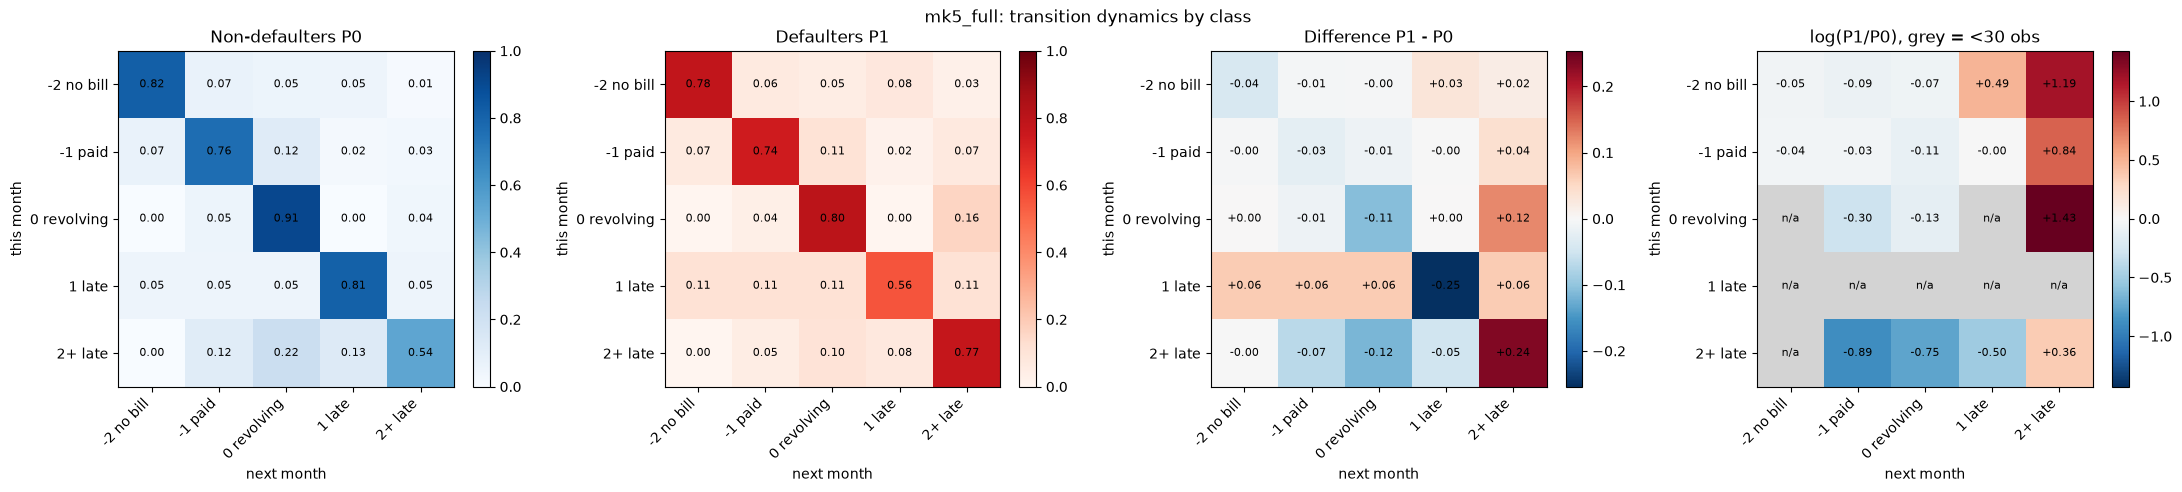

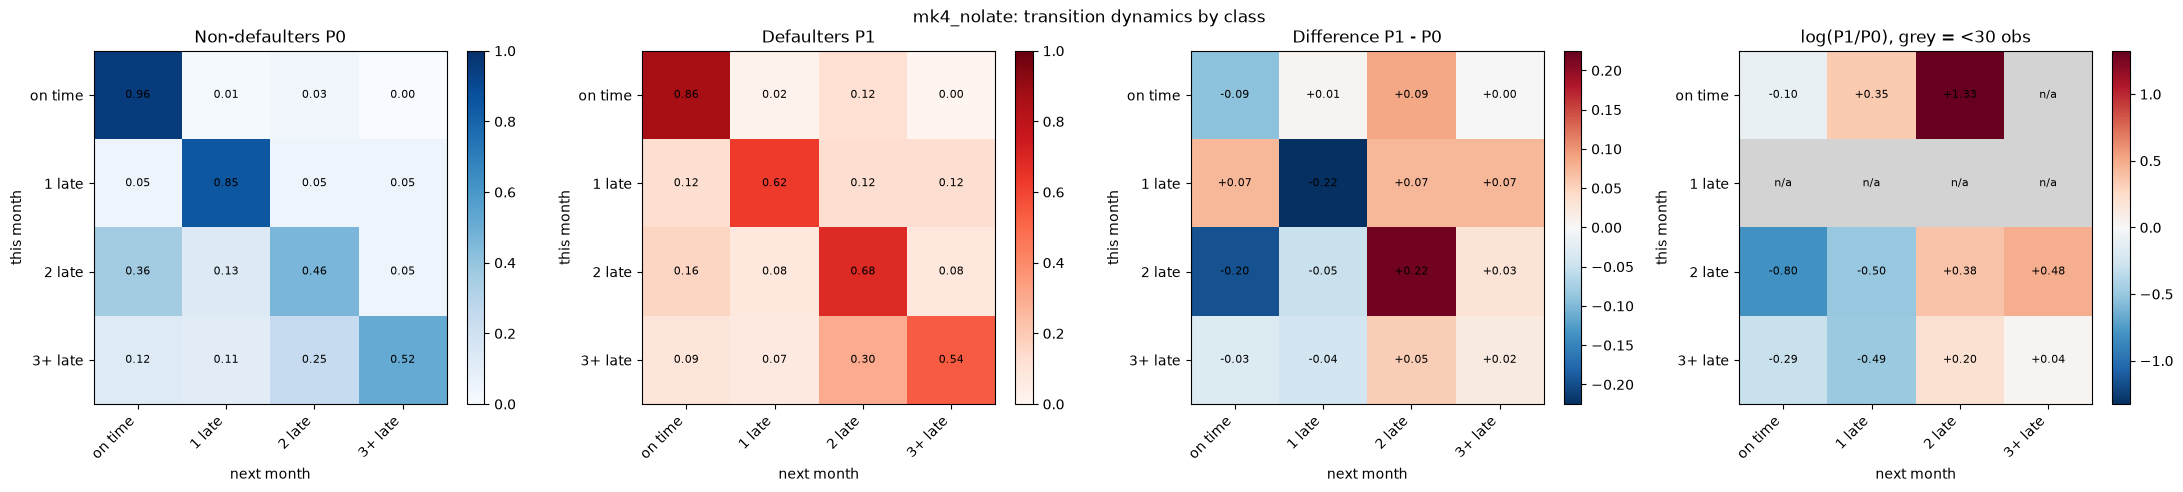

In [111]:
labels_1 = {
    "mk5_full":     ["-2 no bill", "-1 paid", "0 revolving", "1 late", "2+ late"],
    "mk4_nolate":   ["on time", "1 late", "2 late", "3+ late"],
}

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def _prep(key, models, labels, data, pay_cols, y):
    m = models[key]; K = m["K"]
    lab = labels[key] if isinstance(labels, dict) else list(labels)
    assert len(lab) == K, f"{key}: {len(lab)} labels but K={K}"
    y = np.asarray(y)
    S = m["to_state"](data[pay_cols].values)
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    return m, K, lab, C0, C1

def _tick_labels(ax, lab):
    K = len(lab)
    ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(lab)
    ax.set_xlabel("next month"); ax.set_ylabel("this month")


def plot_class_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(22, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(1, 4, figsize=figsize)
    panels = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
              (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
              (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
              (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
        _tick_labels(ax, lab)
    fig.suptitle(f"{key}: transition dynamics by class")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1, low=low)



for k in markov_models_1:
    plot_class_heatmaps(k, markov_models_1, labels_1, train, pay_cols, y_tr)